In [ ]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/Challenge 2"
%cd $current_dir

Mounted at /gdrive
/gdrive/My Drive/Challenge 2


In [ ]:
# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
!pip install torchview
from torchview import draw_graph
from tqdm.notebook import tqdm

# Configurazione di TensorBoard e directory
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO


# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.9.0+cu126
Device: cuda


## ⏳ **Data Loading**

In [ ]:
def load_images_from_folder(folder, num_images, file_prefix='img'):
    """
    Load and preprocess images from a specified folder in sequential order.
    Checks for existing .npy files first to speed up loading.

    Args:
        folder (str): Path to the folder containing images
        num_images (int): The total number of images to load, determining the max ID.
        file_prefix (str): Prefix for the image files (e.g., 'img', 'mask').

    Returns:
        np.ndarray: Array of preprocessed images with shape (N, H, W, C)
    """

    # Define the base .npy filename (e.g., 'train_data_img.npy')
    npy_filename = os.path.basename(os.path.normpath(folder)) + f'_{file_prefix}.npy'

    print(f"Loading {npy_filename} from disk...")
    # Attempt to load the .npy file from the constructed full path
    return np.load(npy_filename)



# Load images from the folder
train_path = 'an2dl2526c2/train_data/'
train_img = load_images_from_folder(train_path, num_images=1412, file_prefix='img')

# Load images from the folder
test_path = 'an2dl2526c2/test_data/'
test_img = load_images_from_folder(test_path, num_images=954, file_prefix='img')

print(f"Loaded {len(train_img)} train images")
print(f"Loaded {len(test_img)} test images")

Loading train_data_img.npy from disk...
Loading test_data_img.npy from disk...
Loaded 1412 train images
Loaded 954 test images


In [ ]:
def load_masks_from_folder(folder, num_images, file_prefix='mask'):
    """
    Load and preprocess images from a specified folder in sequential order.
    Checks for existing .npy files first to speed up loading.

    Args:
        folder (str): Path to the folder containing images
        num_images (int): The total number of images to load, determining the max ID.
        file_prefix (str): Prefix for the mask files (e.g., 'mask').

    Returns:
        np.ndarray: Array of preprocessed images with shape (N, H, W, C)
    """
    # Define the .npy filename based on the folder name and prefix
    npy_filename = os.path.basename(os.path.normpath(folder)) + f'_{file_prefix}.npy'
    print(f"Loading {npy_filename} from disk...")
    return np.load(npy_filename)


# Load masks from the folder
train_path = 'an2dl2526c2/train_data/'
train_masks = load_masks_from_folder(train_path, num_images=1412, file_prefix='masks')

# Load masks from the folder
test_path = 'an2dl2526c2/test_data/'
test_masks = load_masks_from_folder(test_path, num_images=954, file_prefix='masks')

print(f"Loaded {len(train_masks)} train masks")
print(f"Loaded {len(test_masks)} test masks")

Loading train_data_masks.npy from disk...
Loading test_data_masks.npy from disk...
Loaded 1412 train masks
Loaded 954 test masks


## 🔄 **Data Augmentation**

In [ ]:
# Concatenate 'animals' and 'items' arrays along axis 0
X_train = train_img;
X_test = test_img;
y_train = pd.read_csv("an2dl2526c2/train_labels.csv")["label"];

# Define a mapping of classes to integer labels
label_mapping = {
    'Luminal A': 0,
    'Luminal B': 1,
    'HER2(+)': 2,
    'Triple negative': 3,
}

y_train = y_train.map(label_mapping);


In [ ]:
# Define the input shape based on the training data
input_shape = (X_train.shape[3], X_train.shape[1], X_train.shape[2])

# Define the number of classes
num_classes = len(np.unique(y_train))

print("Input Shape:", input_shape)
print("Number of Classes:", num_classes)

Input Shape: (3, 224, 224)
Number of Classes: 4


In [ ]:
# Define the batch size
BATCH_SIZE = 64

In [ ]:
# ImageNet normalization statistics
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class chaldataset(torch.utils.data.Dataset):
    """Custom PyTorch Dataset for Oxford Pets with optional augmentation and normalization."""

    def __init__(self, data, labels, augmentation=None, normalize_imagenet=False):
        """
        Args:
            data: numpy array of images (N, C, H, W) in range [0, 1]
            labels: numpy array of labels
            augmentation: transforms for data augmentation
            normalize_imagenet: whether to apply ImageNet normalization
        """
        self.data = torch.from_numpy(data)
        self.labels = torch.from_numpy(labels).long()
        self.augmentation = augmentation
        self.normalize_imagenet = normalize_imagenet

        # ImageNet normalization transform
        if normalize_imagenet:
            self.normalize = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
        else:
            self.normalize = None

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx].clone()  # Clone to avoid modifying original
        label = self.labels[idx]

        # Permute image dimensions from HWC to CHW
        image = image.permute(2, 0, 1)

        # Apply augmentation if provided (on images in [0, 1] range)
        if self.augmentation:
            image = self.augmentation(image)

        # Apply ImageNet normalization if requested
        if self.normalize:
            image = self.normalize(image)

        return image, label

In [ ]:
def make_loader(ds, batch_size, shuffle, drop_last):
    """Create a PyTorch DataLoader with optimized settings."""
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,
    )

##  🧮 **Network Parameters**

In [ ]:
# Training parameters
LEARNING_RATE = 1e-3
EPOCHS = 200
PATIENCE = 40

# Regularization
DROPOUT_RATE = 0.4

# Set up loss function
criterion = nn.CrossEntropyLoss()

# Print the defined parameters
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)
print("Dropout Rate:", DROPOUT_RATE)
print("Patience:", PATIENCE)

Epochs: 200
Batch Size: 64
Learning Rate: 0.001
Dropout Rate: 0.4
Patience: 40


## 🔎 **Cleaning**

In [ ]:
#@title Resnet Importing

class ResnetB0TransferLearning(nn.Module):
    """ResnetNet-B0 with ImageNet pretrained weights."""

    def __init__(self, num_classes, dropout_rate=0.3, freeze_backbone=True, in_channels=3):
        super().__init__()

        # Load weights pretrained on ImageNet
        self.backbone = torchvision.models.resnet50(
            weights=torchvision.models.ResNet50_Weights.DEFAULT
        )

        # If in_channels is not 3, need to modify the first convolutional layer
        if in_channels != 3:
            original_first_conv = self.backbone.conv1
            self.backbone.conv1 = nn.Conv2d(
                in_channels=in_channels,
                out_channels=original_first_conv.out_channels,
                kernel_size=original_first_conv.kernel_size,
                stride=original_first_conv.stride,
                padding=original_first_conv.padding,
                bias=original_first_conv.bias
            )
            # Copy weights from the original 3 channels to the new 4 channels (e.g., duplicate one channel's weights)
            if original_first_conv.weight is not None:
                new_weight = torch.empty(self.backbone.conv1.weight.shape)
                # Copy original 3 channel weights
                new_weight[:, :3, :, :] = original_first_conv.weight.data
                # Duplicate one channel's weights for the new channel (e.g., red channel)
                new_weight[:, 3:in_channels, :, :] = original_first_conv.weight.data[:, 0:1, :, :]
                self.backbone.conv1.weight = nn.Parameter(new_weight)


        # Freeze all backbone layers if requested
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        # Replace classifier (Always trainable)
        # For ResNet, the classifier is named 'fc'
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()

        # Ensure the new classifier parameters are trainable even if freeze_backbone is True
        for param in self.backbone.fc.parameters():
            param.requires_grad = True

    def forward(self, x):
        return self.backbone(x)

# Create transfer learning model
tl_model = ResnetB0TransferLearning(num_classes, 0.3, freeze_backbone=True, in_channels=input_shape[0]).to(device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 166MB/s]


In [ ]:
#@title Feature extraction of impurities

import numpy as np
import os
import cv2 # Import OpenCV for image resizing

# List of NPY files to load for feature extraction
npy_files = ["shrek_filter1.npy", "shrek_filter2.npy", "scracchio_finale.npy"]
images_to_extract = []

# Define the target size for resizing (from input_shape)
target_height, target_width = input_shape[1], input_shape[2]

print("Loading NPY files...")
for file_name in npy_files:
    # Assuming the files are in the current working directory
    if os.path.exists(file_name):
        img_array = np.load(file_name)

        # Convert to float32 and scale to 0-1 range
        img_array = img_array.astype(np.float32) / 255.0

        # Resize image to target_height x target_width if not already that size
        if img_array.shape[0] != target_height or img_array.shape[1] != target_width:

            img_array = cv2.resize(img_array, (target_width, target_height), interpolation=cv2.INTER_AREA)

        images_to_extract.append(img_array)

    else:
        print(f"Error: File not found - {file_name}. Please ensure the files are in the current directory or provide the full path.")

# Only proceed if images were successfully loaded
if images_to_extract:
    # Combine into a single numpy array
    # All images now have a consistent shape due to resizing
    images_to_extract = np.array(images_to_extract)

    # Create dummy labels for the chaldataset (labels are not used for feature extraction)
    dummy_labels = np.zeros(images_to_extract.shape[0], dtype=int)

    # Use chaldataset for consistent preprocessing (especially normalization)
    # No augmentation needed for feature extraction, but ImageNet normalization is crucial
    feature_extraction_ds = chaldataset(images_to_extract, dummy_labels, augmentation=None, normalize_imagenet=True)
    feature_extraction_loader = make_loader(feature_extraction_ds, BATCH_SIZE, shuffle=False, drop_last=False)

    # Ensure the model is in evaluation mode
    tl_model.eval()


    extracted_features = []
    with torch.no_grad(): # Disable gradient calculation for inference
        for inputs, _ in feature_extraction_loader:
            inputs = inputs.to(device)
            features = tl_model(inputs) # tl_model is configured for feature_extraction mode
            extracted_features.append(features.cpu().numpy())

    extracted_features = np.concatenate(extracted_features, axis=0)


    for i, feats in enumerate(extracted_features):
        print(f"Image {i+1}: {feats[:5]}")
else:
    print("No images were loaded, skipping feature extraction.")


features_shrek1 = extracted_features[0]
features_shrek2 = extracted_features[1]
features_scracchio = extracted_features[2]


Loading NPY files...
Image 1: [0.01352088 0.02205223 0.08612248 0.00551924 0.2591459 ]
Image 2: [0.00560316 0.14864962 0.4516452  1.4161234  0.00216262]
Image 3: [0.         0.08105013 0.4812009  0.         0.06138206]


In [ ]:
#@title Feature extaction on the whole dataset

# 1. Feature Extraction for X_train

# Create dummy labels for X_train (labels are not used for feature extraction)
dummy_labels_train = np.zeros(X_train.shape[0], dtype=int)

# Create chaldataset for X_train with ImageNet normalization
X_train_ds = chaldataset(X_train, dummy_labels_train, augmentation=None, normalize_imagenet=True)
X_train_loader = make_loader(X_train_ds, BATCH_SIZE, shuffle=False, drop_last=False)

# Extract features for X_train
print("\nExtracting features for X_train...")
X_train_features = []
tl_model.eval() # Ensure model is in evaluation mode
with torch.no_grad(): # Disable gradient calculation for inference
    for inputs, _ in tqdm(X_train_loader, desc="Feature extraction for X_train"):
        inputs = inputs.to(device)
        features = tl_model(inputs) # tl_model is configured for feature_extraction mode
        X_train_features.append(features.cpu().numpy())

X_train_features = np.concatenate(X_train_features, axis=0)
print(f"Shape of X_train features: {X_train_features.shape}")



Extracting features for X_train...


Feature extraction for X_train:   0%|          | 0/23 [00:00<?, ?it/s]

Shape of X_train features: (1412, 2048)


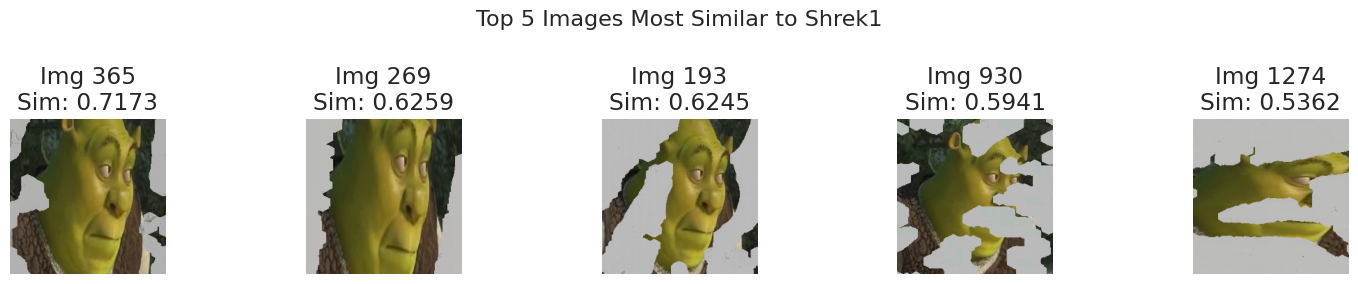

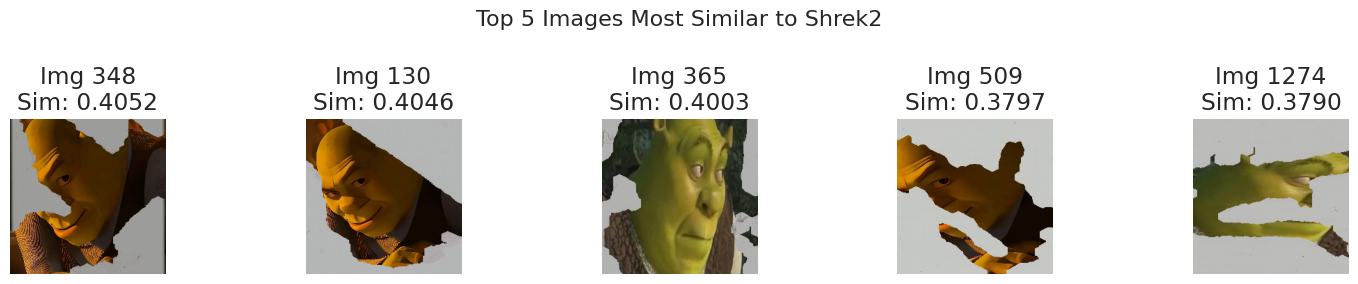

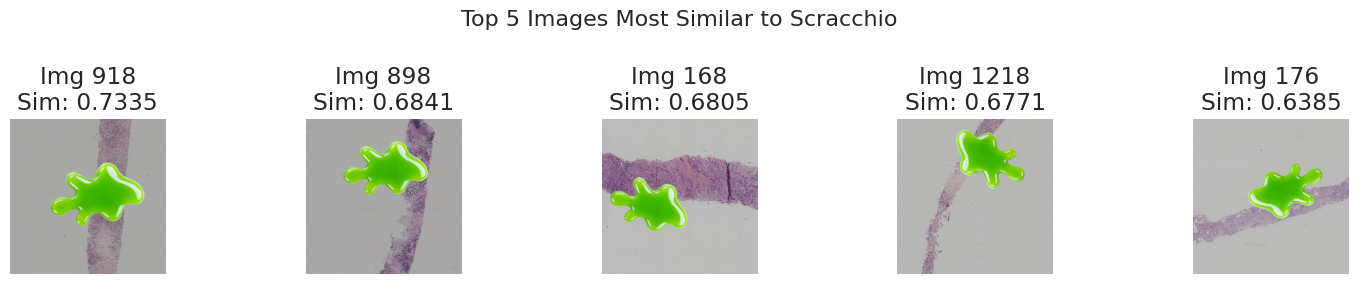

In [ ]:
#@title Cosine Similarity and plotting of the most correlated
from sklearn.metrics.pairwise import cosine_similarity

# Reshape single feature vectors to 2D arrays for sklearn.metrics.pairwise.cosine_similarity
# It expects input in the format (n_samples, n_features)
features_shrek1_2d = features_shrek1.reshape(1, -1)
features_shrek2_2d = features_shrek2.reshape(1, -1)
features_scracchio_2d = features_scracchio.reshape(1, -1)

cosine_sim_shrek1 = cosine_similarity(X_train_features, features_shrek1_2d)
cosine_sim_shrek2 = cosine_similarity(X_train_features, features_shrek2_2d)
cosine_sim_scracchio = cosine_similarity(X_train_features, features_scracchio_2d)

# Display top 5 X_train images most similar to each reference image
top_5_shrek1_indices = np.argsort(cosine_sim_shrek1[:, 0])[::-1][:5]
top_5_shrek2_indices = np.argsort(cosine_sim_shrek2[:, 0])[::-1][:5]
top_5_scracchio_indices = np.argsort(cosine_sim_scracchio[:, 0])[::-1][:5]


def plot_images_by_indices(title, indices, X_data, cosine_similarities, images_per_row=5):
    """
    Plots images from X_data based on a list of indices, with their similarity scores.

    Args:
        title (str): Title for the plot.
        indices (np.ndarray): Array of image indices to plot.
        X_data (np.ndarray): Original image data (e.g., X_train).
        cosine_similarities (np.ndarray): Array of cosine similarities corresponding to X_data.
        images_per_row (int): Number of images to display per row.
    """
    num_images = len(indices)
    num_cols = images_per_row
    num_rows = (num_images + num_cols - 1) // num_cols  # Ceiling division

    fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 3, num_rows * 3))
    axes = axes.flatten() # Flatten the array of axes for easy iteration

    plt.suptitle(title, fontsize=16)

    for i, idx in enumerate(indices):
        ax = axes[i]
        ax.imshow(np.clip(X_data[idx], 0, 1)) # Clip to 0-1 range for display
        ax.set_title(f"Img {idx}\nSim: {cosine_similarities[idx, 0]:.4f}")
        ax.axis('off')

    # Hide any unused subplots if num_images is not a multiple of images_per_row
    for j in range(num_images, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Display images for Shrek1
plot_images_by_indices("Top 5 Images Most Similar to Shrek1", top_5_shrek1_indices, X_train, cosine_sim_shrek1)

# Display images for Shrek2
plot_images_by_indices("Top 5 Images Most Similar to Shrek2", top_5_shrek2_indices, X_train, cosine_sim_shrek2)

# Display images for Scracchio
plot_images_by_indices("Top 5 Images Most Similar to Scracchio", top_5_scracchio_indices, X_train, cosine_sim_scracchio)

In [ ]:
#@title Finding boundaries

top_100_shrek1_indices = np.argsort(cosine_sim_shrek1[:, 0])[::-1][:100]

# Now calling the modified function to plot 5 images per row
plot_images_by_indices("Top 100 Images Most Similar to Shrek1",
                       top_100_shrek1_indices, X_train, cosine_sim_shrek1, images_per_row=5)


top_100_shrek2_indices = np.argsort(cosine_sim_shrek2[:, 0])[::-1][:100]

# Now calling the modified function to plot 5 images per row
plot_images_by_indices("Top 100 Images Most Similar to Shrek2",
                       top_100_shrek2_indices, X_train, cosine_sim_shrek2, images_per_row=5)


top_200_scracchio_indices = np.argsort(cosine_sim_scracchio[:, 0])[::-1][:200]

# Now calling the modified function to plot 5 images per row
plot_images_by_indices("Top 200 Images Most Similar to Scracchio",
                       top_200_scracchio_indices, X_train, cosine_sim_scracchio, images_per_row=5)

#right threeshold for sherek1 is 0.3
#right threeshold for sherek2 is 0.24
#right threeshold for scracchio is 0.385

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
#@title First dataset cleaning

# Define the thresholds
THRESHOLD_SHREK1 = 0.3
THRESHOLD_SHREK2 = 0.24
THRESHOLD_SCRACCHIO = 0.385

print(f"Original X_train shape: {X_train.shape}")
print(f"Original y_train shape: {y_train.shape}")
print(f"Original cosine_sim_shrek1 shape: {cosine_sim_shrek1.shape}")
print(f"Original cosine_sim_shrek2 shape: {cosine_sim_shrek2.shape}")
print(f"Original cosine_sim_scracchio shape: {cosine_sim_scracchio.shape}")

# Calculate boolean masks for images to keep (i.e., similarity is NOT above the threshold)
keep_shrek1 = cosine_sim_shrek1[:, 0] <= THRESHOLD_SHREK1
keep_shrek2 = cosine_sim_shrek2[:, 0] <= THRESHOLD_SHREK2
keep_scracchio = cosine_sim_scracchio[:, 0] <= THRESHOLD_SCRACCHIO

# Combine the masks: an image is kept if it does not exceed ANY of the thresholds
# This means: keep if (sim_shrek1 <= thresh_shrek1) AND (sim_shrek2 <= thresh_shrek2) AND (sim_scracchio <= thresh_scracchio)
images_to_keep_mask = keep_shrek1 & keep_shrek2 & keep_scracchio

# Apply the mask to X_train and y_train
X_train = X_train[images_to_keep_mask]
y_train = y_train[images_to_keep_mask]

# Apply the same mask to the cosine similarity vectors
cosine_sim_shrek1 = cosine_sim_shrek1[images_to_keep_mask]
cosine_sim_shrek2 = cosine_sim_shrek2[images_to_keep_mask]
cosine_sim_scracchio = cosine_sim_scracchio[images_to_keep_mask]

print(f"\nFiltered X_train shape: {X_train.shape}")
print(f"Filtered y_train shape: {y_train.shape}")
print(f"Filtered cosine_sim_shrek1 shape: {cosine_sim_shrek1.shape}")
print(f"Filtered cosine_sim_shrek2 shape: {cosine_sim_shrek2.shape}")
print(f"Filtered cosine_sim_scracchio shape: {cosine_sim_scracchio.shape}")

print(f"Number of images removed: {len(images_to_keep_mask) - images_to_keep_mask.sum()}")

Original X_train shape: (1412, 224, 224, 3)
Original y_train shape: (1412,)
Original cosine_sim_shrek1 shape: (1412, 1)
Original cosine_sim_shrek2 shape: (1412, 1)
Original cosine_sim_scracchio shape: (1412, 1)

Filtered X_train shape: (1214, 224, 224, 3)
Filtered y_train shape: (1214,)
Filtered cosine_sim_shrek1 shape: (1214, 1)
Filtered cosine_sim_shrek2 shape: (1214, 1)
Filtered cosine_sim_scracchio shape: (1214, 1)
Number of images removed: 198


In [ ]:
#@title Human fine tuning
top_40_shrek1_indices = np.argsort(cosine_sim_shrek1[:, 0])[::-1][:150]

# Now calling the modified function to plot 5 images per row
plot_images_by_indices("Top 40 Images Most Similar to Shrek1",
                       top_40_shrek1_indices, X_train, cosine_sim_shrek1, images_per_row=5)


top_40_shrek2_indices = np.argsort(cosine_sim_shrek2[:, 0])[::-1][:150]

# Now calling the modified function to plot 5 images per row
plot_images_by_indices("Top 40 Images Most Similar to Shrek2",
                       top_40_shrek2_indices, X_train, cosine_sim_shrek2, images_per_row=5)


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
print(f"Original X_train shape: {X_train.shape}")
print(f"Original y_train shape: {y_train.shape}")

# User-provided indices to remove
user_indices_to_remove_str = "502, 279, 1172, 1183, 1015, 865, 368, 1029, 559, 1086, 539, 826, 1171, 606, 297, 1069, 372, 586, 456, 1120, 292, 873, 1059, 1022, 474, 108, 443, 220, 449,438, 716, 890, 199, 1148, 519, 517, 212, 634, 248, 655, 1051, 710, 456, 1172, 474, 539 502, 973, 559, 1029, 1086, 1051, 865, 108, 449, 279, 368, 1015, 443, 716, 826, 220, 372, 1059, 292, 1148, 1022, 890, 438, 517, 1120, 1069, 199, 1171, 606, 405, 807, 297, 1183, 231, 1089, 655, 634, 578, 519, 705, 248, 212 "

# Clean and parse the string into a list of unique integers
user_indices_to_remove = np.array(list(set(int(idx.strip()) for idx in user_indices_to_remove_str.replace(' ', ',').split(',') if idx.strip())))

# Create a boolean mask to keep all images *not* in the user_indices_to_remove list
current_train_indices = np.arange(len(X_train))
mask_to_keep = ~np.isin(current_train_indices, user_indices_to_remove)

# Apply the mask to X_train and y_train
X_train = X_train[mask_to_keep]
y_train = y_train[mask_to_keep]

# Update the cosine similarity arrays as well, to keep them consistent with the new X_train
cosine_sim_shrek1 = cosine_sim_shrek1[mask_to_keep]
cosine_sim_shrek2 = cosine_sim_shrek2[mask_to_keep]
cosine_sim_scracchio = cosine_sim_scracchio[mask_to_keep]


print(f"\nFiltered X_train shape: {X_train.shape}")
print(f"Filtered y_train shape: {y_train.shape}")
print(f"Number of images removed in this step: {len(mask_to_keep) - mask_to_keep.sum()}")

Original X_train shape: (1214, 224, 224, 3)
Original y_train shape: (1214,)

Filtered X_train shape: (1165, 224, 224, 3)
Filtered y_train shape: (1165,)
Number of images removed in this step: 49


In [ ]:
# Save X_train as a .npy file
np.save('train_data_clean_img.npy', X_train)
print("X_train saved as train_data_clean_img.npy")

# Save y_train as a .npy file
np.save('train_data_clean_label.npy', y_train)
print("y_train saved as train_data_clean_label.npy")

X_train saved as train_data_clean_img.npy
y_train saved as train_data_clean_label.npy
